# Soal 3 · MASTER: pembagian tugas lewat Kafka + Spark SQL akhir
**Big Data** · dijalankan di **PC Master** (1 Master + 4 Worker). Pasangannya: **Soal3_Worker.ipynb** di setiap PC Worker.

**Alur (satu gelombang, pola materi *Kafka_Cuaca*):** Master mengirim 8 tugas sekaligus → tiap Worker mengambil bagian data milik
satu partisi Kafka, mengolahnya dengan **DataFrame & SQL** di Spark lokal, lalu mengirim ringkasan → Master menggabungkan,
menjalankan **Spark SQL akhir**, membandingkan dengan RDD Soal 2, membuat grafik, dan menyimpan **PNG + CSV**.

| Soal | Di Worker | Di Master |
|---|---|---|
| 3a | skema eksplisit, `ts`, `selisih_byte`, view `edits`, data rusak | validasi jumlah baris dan data rusak (Sel 8) |
| 3b | W1–W5 | `SQL_FINAL` (i)–(iv) + pembanding RDD (Sel 9) |
| 3c | W6–W7 (`window()` 5 menit) | persentil → **k**, daftar lonjakan (Sel 10) |
| 3d | `explain()`, E2, E5, metrik stage | tabel performa dan rencana (Sel 11) |

**Sebelum mulai:** broker Kafka di PC ini berjalan (`advertised.listeners` = `MASTER_IP`); folder `C:\BigData\data\snapshot_wiki\`
berisi file asli, manifest, file uji, dan kunci sisipan. **Urutan:** Sel 1 → 2 → 3 (tunggu 4/4 Worker) → 4 → 5 → 6 → … → 12.
Sel 13 hanya jika ada tugas gagal.

## Sel 1. Konfigurasi, tabel referensi wiki → bahasa, kueri SQL akhir, dan topic

In [1]:
# ===== SEL 1: Konfigurasi, tabel referensi, SQL akhir, dan topic =====
import os, sys, io, json, time, uuid, math, socket
from pathlib import Path
from collections import Counter, defaultdict
from operator import add
import pandas as pd
from confluent_kafka import Producer, Consumer, KafkaError
from confluent_kafka.admin import AdminClient, NewTopic

# ---------------- ISI SESUAI KELOMPOK ----------------
KELOMPOK  = "wiki3"
MASTER_IP = "192.168.1.15"
N_WORKER  = 4
DATA_DIR  = Path("C:/BigData/data/snapshot_wiki")
ZONA      = "Asia/Jakarta"          # sama untuk Master dan Worker (dikirim di tugas)
FAKTOR_PERBESAR     = 20            # data diperbesar khusus percobaan performa (3d)
MAX_PARTITION_BYTES = "8m"          # agar stage pertama > 1 task
K_MANUAL  = None                    # isi angka jika ingin menimpa k hasil aturan (3c)
# ------------------------------------------------------

BOOTSTRAP    = f"{MASTER_IP}:9092"
TOPIC_TUGAS  = f"{KELOMPOK}-tugas"
TOPIC_HASIL  = f"{KELOMPOK}-hasil"
TOPIC_STATUS = f"{KELOMPOK}-status"
JUMLAH_TUGAS = 2 * N_WORKER          # tugas 0..3 olah, 4..7 performa
RUN_ID       = uuid.uuid4().hex[:8]
LAPORAN_DIR  = Path("laporan_soal3"); LAPORAN_DIR.mkdir(exist_ok=True)
F_ASLI, F_UJI = DATA_DIR / "wiki_snapshot.jsonl", DATA_DIR / "wiki_snapshot_uji.jsonl"
F_MANIFEST, F_KUNCI = DATA_DIR / "wiki_snapshot.manifest.json", DATA_DIR / "wiki_snapshot_uji.sisipan.json"

# Tabel referensi (dimension table) wiki -> bahasa, untuk percobaan broadcast join (3d)
BAHASA = {
    "en": "Inggris", "simple": "Inggris Sederhana", "de": "Jerman", "fr": "Prancis", "es": "Spanyol", "it": "Italia",
    "pt": "Portugis", "ru": "Rusia", "ja": "Jepang", "zh": "Tionghoa", "ar": "Arab", "arz": "Arab Mesir", "fa": "Persia",
    "pl": "Polandia", "nl": "Belanda", "sv": "Swedia", "uk": "Ukraina", "vi": "Vietnam", "tr": "Turki", "ko": "Korea",
    "he": "Ibrani", "cs": "Ceko", "hu": "Hungaria", "fi": "Finlandia", "no": "Norwegia", "da": "Denmark",
    "ca": "Katalan", "ro": "Rumania", "el": "Yunani", "th": "Thai", "hi": "Hindi", "bn": "Bengali", "ta": "Tamil",
    "ur": "Urdu", "ceb": "Cebuano", "tl": "Tagalog", "sr": "Serbia", "hr": "Kroasia", "bg": "Bulgaria",
    "eu": "Basque", "gl": "Galisia", "id": "Indonesia", "ms": "Melayu", "jv": "Jawa", "su": "Sunda",
    "min": "Minangkabau", "ban": "Bali", "ace": "Aceh", "bug": "Bugis", "map_bms": "Banyumasan",
}
PROYEK = ["wiki", "wiktionary", "wikibooks", "wikinews", "wikiquote", "wikisource", "wikiversity", "wikivoyage"]
MULTI = ["wikidatawiki", "commonswiki", "metawiki", "specieswiki", "mediawikiwiki", "sourceswiki",
         "incubatorwiki", "foundationwiki", "outreachwiki", "wikifunctionswiki"]
WIKI_REF = ([[k + p, k, b] for k, b in BAHASA.items() for p in PROYEK]
            + [[w, "mul", "multibahasa"] for w in MULTI])

# Kueri SQL akhir (view gabungan: per_menit, bot_wiki, selisih_ringkas, selisih_hist, idwiki_halaman, jendela_hist, kandidat)
SQL_FINAL = {
"i_top5": """
SELECT wiki, SUM(n) AS total_edit, RANK() OVER (ORDER BY SUM(n) DESC) AS peringkat
FROM per_menit GROUP BY wiki ORDER BY peringkat LIMIT 5""",
"i_deret": """
SELECT p.wiki, to_timestamp(p.menit, 'yyyy-MM-dd HH:mm') AS menit, SUM(p.n) AS n
FROM per_menit p JOIN top5 t ON p.wiki = t.wiki
GROUP BY p.wiki, p.menit ORDER BY p.wiki, menit""",
"i_ringkas": """
SELECT wiki, COUNT(*) AS menit_aktif, SUM(n) AS total_edit,
       ROUND(AVG(n), 2) AS rata_per_menit, percentile(n, 0.5) AS median_per_menit, MAX(n) AS maks_per_menit
FROM deret GROUP BY wiki ORDER BY total_edit DESC""",
"ii_bot_manusia": """
SELECT wiki, total, bot, manusia,
       ROUND(100.0 * bot / total, 2)     AS persen_bot,
       ROUND(100.0 * manusia / total, 2) AS persen_manusia
FROM (SELECT wiki, SUM(n) AS total,
             SUM(CASE WHEN bot THEN n ELSE 0 END)     AS bot,
             SUM(CASE WHEN NOT bot THEN n ELSE 0 END) AS manusia
      FROM bot_wiki GROUP BY wiki) t
ORDER BY total DESC, wiki""",
"iii_selisih": """
SELECT r.type, r.n, ROUND(r.jumlah_abs / r.n, 2) AS rata_abs, m.median_eksak
FROM (SELECT type, SUM(n) AS n, SUM(jumlah_abs) AS jumlah_abs FROM selisih_ringkas GROUP BY type) r
JOIN (SELECT type, percentile(nilai_abs, 0.5, frekuensi) AS median_eksak FROM selisih_hist GROUP BY type) m
  ON r.type = m.type
ORDER BY r.type""",
"iv_idwiki": """
SELECT title, editor_unik, n_edit, n_bot
FROM idwiki_halaman
ORDER BY editor_unik DESC, n_edit DESC, title LIMIT 10""",
"c_persentil": """
SELECT kelompok, SUM(frekuensi) AS jumlah_jendela,
       percentile(n, array(0.5, 0.9, 0.95, 0.99, 0.995, 0.999), frekuensi) AS p
FROM jendela_hist GROUP BY kelompok""",
}

admin = AdminClient({"bootstrap.servers": BOOTSTRAP})
daftar = [NewTopic(TOPIC_TUGAS,  num_partitions=N_WORKER, replication_factor=1),
          NewTopic(TOPIC_HASIL,  num_partitions=3,        replication_factor=1),
          NewTopic(TOPIC_STATUS, num_partitions=3,        replication_factor=1)]
for nama, hasil in admin.create_topics(daftar).items():
    try:
        hasil.result(); print("Topic dibuat :", nama)
    except Exception as e:
        print("Dilewati     :", nama, "->", str(e)[:80])
for _ in range(10):
    meta = admin.list_topics(timeout=5)
    if TOPIC_TUGAS in meta.topics:
        break
    time.sleep(1)
print(f"Partisi {TOPIC_TUGAS}: {len(meta.topics[TOPIC_TUGAS].partitions)} (harus {N_WORKER})")
print("RUN_ID:", RUN_ID, "| tabel referensi wiki_ref:", len(WIKI_REF), "baris")
for f in (F_ASLI, F_UJI, F_MANIFEST, F_KUNCI):
    print(f"  {f.name:<34} {'ADA' if f.exists() else 'TIDAK ADA'}")

Dilewati     : wiki3-tugas -> KafkaError{code=TOPIC_ALREADY_EXISTS,val=36,str="Topic 'wiki3-tugas' already exi
Dilewati     : wiki3-hasil -> KafkaError{code=TOPIC_ALREADY_EXISTS,val=36,str="Topic 'wiki3-hasil' already exi
Dilewati     : wiki3-status -> KafkaError{code=TOPIC_ALREADY_EXISTS,val=36,str="Topic 'wiki3-status' already ex
Partisi wiki3-tugas: 4 (harus 4)
RUN_ID: 3930cfca | tabel referensi wiki_ref: 410 baris
  wiki_snapshot.jsonl                ADA
  wiki_snapshot_uji.jsonl            ADA
  wiki_snapshot.manifest.json        ADA
  wiki_snapshot_uji.sisipan.json     ADA


## Sel 2. Consumer Master dan fungsi monitor
Setiap potongan ringkasan disimpan dengan kunci unik `(tugas, tabel, nomor)`, sehingga kiriman ganda otomatis tertimpa. Tugas **lengkap** hanya jika jumlah potongan yang diterima sama dengan yang dijanjikan Worker.

In [2]:
# ===== SEL 2: Consumer Master, status, dan monitor =====
from IPython.display import clear_output, display

konsumen = Consumer({
    "bootstrap.servers": BOOTSTRAP,
    "group.id": f"{KELOMPOK}-master-{RUN_ID}",
    "auto.offset.reset": "earliest",
    "enable.auto.commit": True,
    "fetch.max.bytes": 52428800,
})
konsumen.subscribe([TOPIC_HASIL, TOPIC_STATUS])

AKTIF_DETIK = 120
terdaftar, terlihat, status = {}, {}, {}
selesai, gagal = set(), set()
harapan, diterima = {}, Counter()
pelaksana, info_tugas = defaultdict(set), {}
potongan = {}                          # (tugas, tabel, no) -> {"worker":..., "baris": [...]}
NAMA_TUGAS = {}

def sedot(detik=2.0):
    akhir = time.time() + detik
    while time.time() < akhir:
        msg = konsumen.poll(0.2)
        if msg is None:
            continue
        if msg.error():
            if msg.error().code() != KafkaError._PARTITION_EOF:
                print("Kafka:", msg.error())
            continue
        try:
            d = json.loads(msg.value())
        except ValueError:
            continue
        if msg.topic() == TOPIC_STATUS:
            w, st = d.get("worker"), d.get("status")
            if w is None:
                continue
            terlihat[w] = max(terlihat.get(w, 0), d.get("waktu", 0))
            if st == "SIAP":
                terdaftar[w] = d.get("partisi", [])
            elif st == "BERHENTI":
                terdaftar.pop(w, None); terlihat.pop(w, None)
            elif st == "HIDUP":
                pass
            elif d.get("run") == RUN_ID:
                status[w] = d
                t = d["tugas"]
                if st == "SELESAI":
                    selesai.add(t); gagal.discard(t)
                    harapan[t] = d.get("jumlah", 0); pelaksana[t].add(w); info_tugas[t] = d
                elif st == "GAGAL":
                    gagal.add(t); info_tugas[t] = d
        elif d.get("run") == RUN_ID:
            kunci = (d["tugas"], d["tabel"], d["no"])
            if kunci not in potongan:
                diterima[d["tugas"]] += 1
            potongan[kunci] = {"worker": d["worker"], "baris": d["baris"]}

def lengkap():
    return {t for t in selesai if diterima[t] >= harapan.get(t, 0)}

def tampilkan():
    sekarang = time.time()
    aktif = {w for w in terdaftar if sekarang - terlihat.get(w, 0) < AKTIF_DETIK}
    lgk = lengkap()
    print("=" * 92)
    print(f"  MONITOR {KELOMPOK} - SOAL 3 SPARK DATAFRAME & SQL | RUN {RUN_ID}")
    print("=" * 92)
    print(f"Worker aktif: {len(aktif)}/{N_WORKER} | Tugas selesai: {len(selesai)}/{JUMLAH_TUGAS} | "
          f"Data lengkap: {len(lgk)}/{JUMLAH_TUGAS} | Gagal: {len(gagal)} | Potongan diterima: {len(potongan):,}")
    print("\n--- WORKER ---")
    for w in sorted(aktif):
        s = status.get(w)
        if s:
            print(f"{w:<30} partisi {str(terdaftar[w]):<6} tugas {s['tugas']:>2} [{NAMA_TUGAS.get(s['tugas'], '?'):<14}] "
                  f"{s['status']:<10} {s.get('tahap', '')}")
        else:
            print(f"{w:<30} partisi {str(terdaftar[w]):<6} menunggu tugas")
    if gagal:
        print("\nGAGAL:", {t: info_tugas[t].get("galat", "?") for t in sorted(gagal)})

def monitor(refresh=2, otomatis_berhenti=False):
    try:
        while True:
            sedot(refresh)
            clear_output(wait=True)
            tampilkan()
            if otomatis_berhenti and len(lengkap()) + len(gagal) >= JUMLAH_TUGAS:
                print("\nSEMUA TUGAS SELESAI DAN DATA LENGKAP." if not gagal else
                      f"\nSELESAI, tetapi {len(gagal)} tugas GAGAL: {sorted(gagal)} -> kirim ulang di Sel 13.")
                break
            print(f"\nRefresh {refresh} detik | Interrupt untuk berhenti")
    except KeyboardInterrupt:
        print("\nMonitor dihentikan.")

print("Consumer Master siap.")

Consumer Master siap.


## Sel 3. Tunggu semua Worker siap
Minta anggota menjalankan Sel 1–6 notebook Worker di PC masing-masing. Hentikan sel ini (Interrupt) ketika **Worker aktif = 4/4**.

In [3]:
monitor()

  MONITOR wiki3 - SOAL 3 SPARK DATAFRAME & SQL | RUN 3930cfca
Worker aktif: 4/4 | Tugas selesai: 0/8 | Data lengkap: 0/8 | Gagal: 0 | Potongan diterima: 0

--- WORKER ---
NthaanSnn-w1                   partisi [2]    menunggu tugas
NthaanSnn-w2                   partisi [1]    menunggu tugas
NthaanSnn-w3                   partisi [3]    menunggu tugas
NthaanSnn-w4                   partisi [0]    menunggu tugas

Refresh 2 detik | Interrupt untuk berhenti

Monitor dihentikan.


## Sel 4. Hitung rentang baris dan kirim 8 tugas
Rentang baris tiap partisi Kafka di **file uji** dihitung dari manifest (jumlah baris per partisi) dan kunci sisipan
(posisi 100 baris rusak), tanpa membaca isi data. Baris rusak yang jatuh di antara dua partisi ikut ke partisi sebelumnya.
Di tiap partisi tugas, tugas `olah` dikirim lebih dulu dan tugas `performa` paling akhir.

In [4]:
# ===== SEL 4: Rentang baris per partisi + kirim tugas =====
manifest = json.loads(F_MANIFEST.read_text(encoding="utf-8"))
kunci_sisip = json.loads(F_KUNCI.read_text(encoding="utf-8"))
SISIP = sorted((s["baris"] - 1, s["jenis"]) for s in kunci_sisip["sisipan"])   # indeks 0-based di file uji
POS_SISIP = [p for p, _ in SISIP]
N_UJI = manifest["jumlah_baris"] + len(SISIP)

def posisi_uji(j):
    """Indeks baris asli ke-j (0-based) -> indeks baris yang sama di file uji."""
    pos = j
    for s in POS_SISIP:
        if s <= pos:
            pos += 1
        else:
            break
    return pos

PARTISI = sorted(manifest["partisi"], key=int)
awal_asli, a = {}, 0
for p in PARTISI:
    awal_asli[p] = a
    a += manifest["partisi"][p]["jumlah"]

RENTANG = {}
for i, p in enumerate(PARTISI):
    mulai = 0 if i == 0 else posisi_uji(awal_asli[p])
    akhir = N_UJI if i == len(PARTISI) - 1 else posisi_uji(awal_asli[PARTISI[i + 1]])
    rusak = Counter(j for pos, j in SISIP if mulai <= pos < akhir)
    RENTANG[int(p)] = {"baris_mulai": mulai, "baris_akhir": akhir,
                       "harap_valid": manifest["partisi"][p]["jumlah"], "harap_rusak": dict(rusak)}

print(f"File uji {N_UJI:,} baris (asli {manifest['jumlah_baris']:,} + sisipan {len(SISIP)})")
print(f"{'partisi':>7}{'mulai':>10}{'akhir':>10}{'baris':>9}{'valid':>9}  rusak sisipan")
for p, r in RENTANG.items():
    print(f"{p:>7}{r['baris_mulai']:>10,}{r['baris_akhir']:>10,}{r['baris_akhir'] - r['baris_mulai']:>9,}"
          f"{r['harap_valid']:>9,}  {r['harap_rusak']}")
assert sum(r["baris_akhir"] - r["baris_mulai"] for r in RENTANG.values()) == N_UJI
assert sum(sum(r["harap_rusak"].values()) for r in RENTANG.values()) == len(SISIP)

produser = Producer({"bootstrap.servers": BOOTSTRAP, "acks": "all", "enable.idempotence": True})
galat_kirim = []
def _hasil_kirim(err, msg):
    if err is not None:
        galat_kirim.append(str(err))

def buat_tugas():
    daftar = []
    for p in range(N_WORKER):
        daftar.append({"run": RUN_ID, "tugas": p, "jenis": "olah", "partisi": p, "partisi_kafka": p,
                       "file": F_UJI.name, "zona": ZONA, "dibuat": time.time(), **RENTANG[p]})
    for p in range(N_WORKER):          # performa dikirim PALING AKHIR di tiap partisi
        daftar.append({"run": RUN_ID, "tugas": N_WORKER + p, "jenis": "performa", "partisi": p, "partisi_kafka": p,
                       "file": F_UJI.name, "zona": ZONA, "faktor": FAKTOR_PERBESAR,
                       "max_partition_bytes": MAX_PARTITION_BYTES, "wiki_ref": WIKI_REF,
                       "dibuat": time.time(), **RENTANG[p]})
    return daftar

def kirim_tugas(daftar):
    galat_kirim.clear()
    for t in daftar:
        NAMA_TUGAS[t["tugas"]] = f"{t['jenis']} p{t['partisi_kafka']}"
        produser.produce(TOPIC_TUGAS, key=str(t["tugas"]), value=json.dumps(t).encode("utf-8"),
                         partition=t["partisi"], on_delivery=_hasil_kirim)
    sisa = produser.flush(30)
    print(f"PERINGATAN: belum terkirim={sisa}, galat={galat_kirim[:2]}" if sisa or galat_kirim
          else f"\n{len(daftar)} tugas terkirim & dikonfirmasi broker ke '{TOPIC_TUGAS}'")

SEMUA_TUGAS = buat_tugas()
kirim_tugas(SEMUA_TUGAS)

File uji 222,341 baris (asli 222,241 + sisipan 100)
partisi     mulai     akhir    baris    valid  rusak sisipan
      0         0    54,878   54,878   54,854  {'json_rusak': 7, 'kosong': 9, 'field_wajib': 8}
      1    54,878   111,160   56,282   56,266  {'kosong': 3, 'json_rusak': 7, 'field_wajib': 6}
      2   111,160   166,984   55,824   55,791  {'json_rusak': 17, 'field_wajib': 6, 'kosong': 10}
      3   166,984   222,341   55,357   55,330  {'field_wajib': 10, 'kosong': 8, 'json_rusak': 9}

8 tugas terkirim & dikonfirmasi broker ke 'wiki3-tugas'


## Sel 5. Pantau sampai semua tugas selesai

In [5]:
monitor(otomatis_berhenti=True)

  MONITOR wiki3 - SOAL 3 SPARK DATAFRAME & SQL | RUN 3930cfca
Worker aktif: 4/4 | Tugas selesai: 8/8 | Data lengkap: 8/8 | Gagal: 0 | Potongan diterima: 148

--- WORKER ---
NthaanSnn-w1                   partisi [2]    tugas  6 [performa p2   ] SELESAI    
NthaanSnn-w2                   partisi [1]    tugas  5 [performa p1   ] SELESAI    
NthaanSnn-w3                   partisi [3]    tugas  7 [performa p3   ] SELESAI    
NthaanSnn-w4                   partisi [0]    tugas  4 [performa p0   ] SELESAI    

SEMUA TUGAS SELESAI DAN DATA LENGKAP.


## Sel 6. Bukti pembagian tugas
Siapa mengerjakan tugas apa, berapa baris, dan berapa lama.

In [6]:
# ===== SEL 6: Bukti pembagian tugas =====
print(f"{'TUGAS':<6}{'JENIS':<16}{'DIKERJAKAN OLEH':<32}{'POTONGAN':>9}{'BARIS':>11}{'PROSES(s)':>10}{'TOTAL(s)':>10}")
print("-" * 94)
for t in range(JUMLAH_TUGAS):
    inf = info_tugas.get(t, {})
    print(f"{t:<6}{NAMA_TUGAS.get(t, '-'):<16}{', '.join(sorted(pelaksana[t])) or '-':<32}{diterima[t]:>9}"
          f"{inf.get('baris', 0):>11,}{inf.get('detik_proses', 0):>10}{inf.get('detik_total', 0):>10}")
per_worker = Counter(w for t in range(JUMLAH_TUGAS) for w in pelaksana[t])
print(f"\nWorker yang bekerja : {len(per_worker)} dari {N_WORKER} -> {dict(per_worker)}")
print(f"Tugas tanpa pelaksana: {[t for t in range(JUMLAH_TUGAS) if not pelaksana[t]]}")
print(f"Tugas dikerjakan >1 worker (sudah digabung aman): {[t for t in range(JUMLAH_TUGAS) if len(pelaksana[t]) > 1]}")

TUGAS JENIS           DIKERJAKAN OLEH                  POTONGAN      BARIS PROSES(s)  TOTAL(s)
----------------------------------------------------------------------------------------------
0     olah p0         NthaanSnn-w4                           33     54,878     18.38     18.46
1     olah p1         NthaanSnn-w2                           33     56,282     18.33     18.42
2     olah p2         NthaanSnn-w1                           33     55,824     18.21     18.32
3     olah p3         NthaanSnn-w3                           33     55,357      18.2     18.32
4     performa p0     NthaanSnn-w4                            4  1,097,080         0     62.14
5     performa p1     NthaanSnn-w2                            4  1,125,320         0     62.87
6     performa p2     NthaanSnn-w1                            4  1,115,820         0     62.95
7     performa p3     NthaanSnn-w3                            4  1,106,600         0     62.61

Worker yang bekerja : 4 dari 4 -> {'NthaanSnn-w4'

## Sel 7. Sesi Spark Master
Spark lokal `local[*]` untuk SQL akhir pada gabungan ringkasan dan untuk sel pembanding RDD.

In [7]:
# ===== SEL 7: Spark Master =====
from pyspark.sql import SparkSession, functions as F

spark = (SparkSession.builder.appName(f"{KELOMPOK}-master-soal3").master("local[*]")
         .config("spark.driver.memory", "2g")
         .config("spark.driver.host", "127.0.0.1").config("spark.driver.bindAddress", "127.0.0.1")
         .config("spark.sql.shuffle.partitions", "8")
         .config("spark.sql.session.timeZone", ZONA)
         .config("spark.pyspark.python", sys.executable)
         .config("spark.pyspark.driver.python", sys.executable)
         .getOrCreate())
sc = spark.sparkContext
sc.setLogLevel("ERROR")
print("Spark", spark.version, "| master:", sc.master, "| UI:", sc.uiWebUrl, "| zona:", spark.conf.get("spark.sql.session.timeZone"))

Spark 4.1.3 | master: local[*] | UI: http://127.0.0.1:4044 | zona: Asia/Jakarta


## Sel 8. Gabungan ringkasan dan validasi (Soal 3a)
Ringkasan keempat Worker dijadikan view Spark dengan skema eksplisit. Validasi: baris valid per partisi = manifest
(total 222.241), data rusak = kunci sisipan (total 100), dan **tidak ada halaman yang muncul di dua Worker** (bukti key `wiki:title`).

In [8]:
# ===== SEL 8: Gabungan + validasi =====
def ambil(tabel, tugas=None):
    """Semua baris satu tabel ringkasan, ditambah kolom 'bagian' (partisi Kafka asal)."""
    keluar = []
    for (t, tb, no), isi in sorted(potongan.items()):
        if tb == tabel and (tugas is None or t in tugas):
            for b in isi["baris"]:
                keluar.append({**b, "bagian": t % N_WORKER, "worker": isi["worker"]})
    return keluar

OLAH = set(range(N_WORKER))
SKEMA_VIEW = {
    "per_menit":       ("W1_per_menit",       "wiki string, menit string, n long, bagian int"),
    "bot_wiki":        ("W2_bot_wiki",        "wiki string, bot boolean, n long, bagian int"),
    "selisih_ringkas": ("W3_selisih_ringkas", "type string, n long, jumlah_abs long, rata_abs double, median_approx long, bagian int"),
    "selisih_hist":    ("W4_selisih_hist",    "type string, nilai_abs long, frekuensi long, bagian int"),
    "idwiki_halaman":  ("W5_idwiki_halaman",  "title string, editor_unik long, n_edit long, n_bot long, bagian int"),
    "jendela_hist":    ("W6_jendela_hist",    "kelompok string, n long, frekuensi long, bagian int"),
    "kandidat":        ("W7_kandidat",        "wiki string, title string, mulai string, n_edit long, n_bot long, "
                                              "n_manusia long, editor_unik long, bagian int"),
}
for view, (tabel, ddl) in SKEMA_VIEW.items():
    kolom = [c.strip().split()[0] for c in ddl.split(",")]
    baris = ambil(tabel, OLAH)
    spark.createDataFrame([tuple(b.get(c) for c in kolom) for b in baris], ddl).createOrReplaceTempView(view)
    print(f"view {view:<16} {len(baris):>9,} baris")

stat = sorted(ambil("W0_statistik", OLAH), key=lambda s: s["partisi_kafka"])
print(f"\n{'p':>2} {'worker':<26}{'valid':>9}{'harap':>9}{'kosong':>7}{'corrupt':>8}{'wajib':>6}{'rusak':>6}{'harap':>6}  rentang ts")
tot_valid = tot_rusak = 0
for s in stat:
    rusak = s["kosong"] + s["rusak_corrupt"] + s["rusak_field_wajib"]
    harap = sum(s["harap_rusak"].values())
    tot_valid += s["n_valid"]; tot_rusak += rusak
    print(f"{s['partisi_kafka']:>2} {s['worker']:<26}{s['n_valid']:>9,}{s['harap_valid']:>9,}{s['kosong']:>7}"
          f"{s['rusak_corrupt']:>8}{s['rusak_field_wajib']:>6}{rusak:>6}{harap:>6}  {s['ts_min']} .. {s['ts_max']}")
print(f"\nTotal valid  : {tot_valid:,} (manifest {manifest['jumlah_baris']:,}) ->",
      "COCOK" if tot_valid == manifest["jumlah_baris"] else "TIDAK COCOK")
print(f"Total rusak  : {tot_rusak} (kunci sisipan {len(SISIP)}) ->", "COCOK" if tot_rusak == len(SISIP) else "TIDAK COCOK")
print("Jenis sisipan (kunci, cara Soal 2a):", dict(Counter(j for _, j in SISIP)))
print("Jenis menurut DataFrame           :", {"kosong (dibuang saat ingest)": sum(s["kosong"] for s in stat),
      "_corrupt_record": sum(s["rusak_corrupt"] for s in stat),
      "field wajib null": sum(s["rusak_field_wajib"] for s in stat)})
print("Per type (gabungan):", dict(sum((Counter(s["per_type"]) for s in stat), Counter())))
if stat:
    print("\nSkema (Worker):", stat[0]["skema"][:160], "...")
    print("Contoh baris edits (Worker p0):")
    display(pd.DataFrame(stat[0]["contoh"]))

dobel = spark.sql("SELECT title, COUNT(DISTINCT bagian) AS b FROM idwiki_halaman GROUP BY title HAVING b > 1").count()
dobel_k = spark.sql("SELECT wiki, title, COUNT(DISTINCT bagian) AS b FROM kandidat GROUP BY wiki, title HAVING b > 1").count()
print(f"\nHalaman idwiki di >1 Worker: {dobel} | halaman kandidat lonjakan di >1 Worker: {dobel_k} (harus 0 dan 0)")

view per_menit           21,253 baris
view bot_wiki             1,176 baris
view selisih_ringkas          8 baris
view selisih_hist        21,241 baris
view idwiki_halaman         315 baris
view jendela_hist           280 baris
view kandidat            10,653 baris

 p worker                        valid    harap kosong corrupt wajib rusak harap  rentang ts
 0 NthaanSnn-w4                 54,854   54,854      9      11     4    24    24  2026-11-18 03:28:48 .. 2026-11-18 07:23:35
 1 NthaanSnn-w2                 56,266   56,266      3      10     3    16    16  2026-11-18 03:28:55 .. 2026-11-18 07:23:35
 2 NthaanSnn-w1                 55,791   55,791     10      20     3    33    33  2026-11-18 03:28:53 .. 2026-11-18 07:23:35
 3 NthaanSnn-w3                 55,330   55,330      8      14     5    27    27  2026-11-18 03:28:56 .. 2026-11-18 07:23:35

Total valid  : 222,241 (manifest 222,241) -> COCOK
Total rusak  : 100 (kunci sisipan 100) -> COCOK
Jenis sisipan (kunci, cara Soal 2a): {'j

,id,wiki,type,title,ts,length_old,length_new,selisih_byte
0,2651834377,wikidatawiki,edit,Q100893590,2026-11-18 03:28:59,12171,12276,105
1,3535906029,commonswiki,edit,File:08.02 副總統出席「2026台灣盃火箭競賽決賽閉幕暨頒獎典禮」 - 55437...,2026-11-18 03:28:58,7510,8382,872
2,386662644,dewiki,edit,Ustetschko (Kremenez),2026-11-18 03:28:58,3187,2932,-255



Halaman idwiki di >1 Worker: 0 | halaman kandidat lonjakan di >1 Worker: 0 (harus 0 dan 0)


## Sel 9. Soal 3b: kueri SQL akhir (i)–(iv) dan pembanding RDD untuk (ii)
"Edit" = `type = 'edit'` (sama dengan Soal 2); (iii) memakai semua type; (iv) menghitung semua `user` idwiki (termasuk bot dan anonim ter-hash).
Persentase (ii) dihitung **setelah** jumlah dari keempat Worker dijumlahkan.

In [9]:
# ===== SEL 9: Soal 3b =====
H = {}
def jalankan(nama, view=None):
    df = spark.sql(SQL_FINAL[nama])
    if view:
        df.createOrReplaceTempView(view)
    H[nama] = df.toPandas()
    H[nama].to_csv(LAPORAN_DIR / f"3b_{nama}.csv", index=False)
    return H[nama]

print("--- (i) 5 wiki teratas (edit) ---");             display(jalankan("i_top5", "top5"))
jalankan("i_deret", "deret")
print("--- (i) ringkasan edit per menit ---");          display(jalankan("i_ringkas"))
print("--- (ii) persentase bot dan manusia (20 wiki terbesar; lengkap di CSV) ---")
display(jalankan("ii_bot_manusia").head(20))
print("--- (iii) abs(selisih_byte) per type ---");      display(jalankan("iii_selisih"))
print("    median perkiraan per Worker (percentile_approx):")
display(spark.sql("SELECT type, bagian, n, median_approx FROM selisih_ringkas ORDER BY type, bagian").toPandas()
        .pivot(index="type", columns="bagian", values="median_approx"))
print("--- (iv) 10 halaman idwiki dengan editor unik terbanyak ---"); display(jalankan("iv_idwiki"))

# Pembanding RDD (pola Soal 2) untuk (ii): dihitung ulang langsung dari file snapshot asli
def kunci_bot(baris):
    import json
    try:
        e = json.loads(baris)
    except ValueError:
        return []
    if isinstance(e, dict) and e.get("type") == "edit" and e.get("wiki"):
        return [((e["wiki"], bool(e.get("bot", False))), 1)]
    return []

t0 = time.time()
rdd_hitung = dict(sc.textFile(F_ASLI.resolve().as_uri(), 8).flatMap(kunci_bot).reduceByKey(add).collect())
sql_hitung = {(r.wiki, r.bot): r.n for r in spark.sql("SELECT wiki, bot, SUM(n) AS n FROM bot_wiki GROUP BY wiki, bot").collect()}
beda = {k: (sql_hitung.get(k, 0), rdd_hitung.get(k, 0)) for k in set(sql_hitung) | set(rdd_hitung)
        if sql_hitung.get(k, 0) != rdd_hitung.get(k, 0)}
print(f"\nPembanding RDD ({time.time() - t0:.1f} dtk): {len({w for w, _ in rdd_hitung})} wiki, "
      f"{sum(rdd_hitung.values()):,} edit | pasangan (wiki, bot) berbeda dengan SQL: {len(beda)} -> "
      + ("KONSISTEN" if not beda else f"TIDAK KONSISTEN {list(beda.items())[:5]}"))

TOP_2B = {"wikidatawiki": 72409, "commonswiki": 17990, "enwiki": 17403, "frwiki": 2424, "dewiki": 2394,
          "eswiki": 1494, "itwiki": 1458, "ptwiki": 1145, "zhwiki": 986, "ruwiki": 958}
ii = H["ii_bot_manusia"].set_index("wiki")
cocok = {w: (int(ii.loc[w, "manusia"]), n) for w, n in TOP_2B.items()}
print("Cocok dengan 10 angka Soal 2b(i) (edit manusia):", all(a == b for a, b in cocok.values()))
pd.DataFrame([(w, a, b) for w, (a, b) in cocok.items()], columns=["wiki", "SQL 3b(ii) manusia", "RDD 2b(i)"]) \
  .to_csv(LAPORAN_DIR / "3b_ii_vs_rdd2b.csv", index=False)

--- (i) 5 wiki teratas (edit) ---


,wiki,total_edit,peringkat
0,wikidatawiki,79897,1
1,commonswiki,51763,2
2,enwiki,24404,3
3,ttwiki,4592,4
4,arwiki,4531,5


--- (i) ringkasan edit per menit ---


,wiki,menit_aktif,total_edit,rata_per_menit,median_per_menit,maks_per_menit
0,wikidatawiki,183,79897,436.60,429.0,1283
1,commonswiki,183,51763,282.86,260.0,950
2,enwiki,183,24404,133.36,135.0,471
3,ttwiki,183,4592,25.09,25.0,42
4,arwiki,183,4531,24.76,20.0,64


--- (ii) persentase bot dan manusia (20 wiki terbesar; lengkap di CSV) ---


,wiki,total,bot,manusia,persen_bot,persen_manusia
0,wikidatawiki,79897,7488,72409,9.37,90.63
1,commonswiki,51763,33773,17990,65.25,34.75
2,enwiki,24404,7001,17403,28.69,71.31
3,ttwiki,4592,4592,0,100.00,0.00
4,arwiki,4531,4325,206,95.45,4.55
5,frwiki,3490,1066,2424,30.54,69.46
6,dewiki,3372,978,2394,29.00,71.00
7,zhwiki,2577,1591,986,61.74,38.26
8,ruwiki,1795,837,958,46.63,53.37
9,itwiki,1789,331,1458,18.50,81.50


... (3 outputs left out)

bagian,0,1,2,3
type,,,,
edit,256,267,259,259
new,2155,2118,2127,2138


--- (iv) 10 halaman idwiki dengan editor unik terbanyak ---


,title,editor_unik,n_edit,n_bot
0,Wikipedia:Bak pasir,2,6,3
1,Universitas Indonesia,1,6,0
2,"Ghanta Ghar, Multan",1,5,0
3,Liga B Liga Negara UEFA 2026–2027,1,4,0
4,Pengguna:PeterJunParker/Bak pasir,1,4,0
5,Regio Patalis,1,4,0
6,Abryna,1,3,0
7,Liga A Liga Negara UEFA 2026–2027,1,3,0
8,Monyet rhesus,1,3,0
9,Pertempuran Radzymin (1920),1,3,0



Pembanding RDD (24.2 dtk): 300 wiki, 202,738 edit | pasangan (wiki, bot) berbeda dengan SQL: 0 -> KONSISTEN
Cocok dengan 10 angka Soal 2b(i) (edit manusia): True


## Sel 10. Soal 3c: deteksi lonjakan dengan jendela 5 menit
Unit = (wiki, title), jendela **tumbling** `window(ts, '5 minutes')`, hanya `type = 'edit'`.
**Aturan k:** k = ⌈p99⌉ distribusi jumlah edit per (halaman, jendela). Karena distribusinya diskret dan sebagian besar jendela
berisi 1 edit, banyak nilai sama; bila porsi jendela dengan jumlah ≥ k lebih dari 2% (dua kali nominal 1%), k naik ke ⌈p99,9⌉.
Dihitung untuk **semua** edit (jawaban soal) dan **manusia saja** (untuk tafsiran).

In [10]:
# ===== SEL 10: Soal 3c =====
LABEL_P = ["p50", "p90", "p95", "p99", "p99,5", "p99,9"]
pers = {r.kelompok: (r.jumlah_jendela, list(r.p)) for r in spark.sql(SQL_FINAL["c_persentil"]).collect()}

def porsi_ge(kelompok, k):
    return spark.sql(f"SELECT SUM(CASE WHEN n >= {k} THEN frekuensi ELSE 0 END) / SUM(frekuensi) AS q "
                     f"FROM jendela_hist WHERE kelompok = '{kelompok}'").first().q

K, ALASAN, KEPEKAAN = {}, {}, []
for kel in ("semua", "manusia"):
    total, p = pers[kel]
    for lab, v in zip(LABEL_P, p):
        k = max(2, math.ceil(v))
        q = porsi_ge(kel, k)
        KEPEKAAN.append({"kelompok": kel, "persentil": lab, "nilai": v, "k": k,
                         "jendela_ge_k": int(round(q * total)), "porsi_ge_k_%": round(100 * q, 3)})
    k99 = max(2, math.ceil(p[3])); q99 = porsi_ge(kel, k99)
    if K_MANUAL:
        K[kel], ALASAN[kel] = K_MANUAL, "ditetapkan manual (K_MANUAL)"
    elif q99 > 0.02:
        K[kel] = max(2, math.ceil(p[5]))
        ALASAN[kel] = (f"p99 = {p[3]:g} -> k = {k99} menangkap {100 * q99:.2f}% jendela (> 2%, terlalu longgar karena "
                       f"nilai kembar), maka dipakai p99,9 = {p[5]:g}")
    else:
        K[kel], ALASAN[kel] = k99, f"p99 = {p[3]:g}; porsi jendela >= k = {100 * q99:.2f}% (dekat nominal 1%)"
    print(f"[{kel}] {total:,} (halaman, jendela) | k = {K[kel]} | {ALASAN[kel]}")

tabel_kepekaan = pd.DataFrame(KEPEKAAN)
tabel_kepekaan.to_csv(LAPORAN_DIR / "3c_kepekaan_k.csv", index=False)
display(tabel_kepekaan)
assert min(K.values()) >= 2, "Worker hanya mengirim kandidat n_edit >= 2"

POLA = """CASE WHEN n_bot = n_edit THEN 'bot saja'
               WHEN editor_unik >= 3 THEN 'banyak editor'
               WHEN n_manusia = n_edit THEN 'manusia, 1-2 editor'
               ELSE 'campuran bot-manusia' END"""
lonjak = spark.sql(f"""SELECT wiki, title, mulai, n_edit, n_bot, n_manusia, editor_unik, {POLA} AS pola
                       FROM kandidat WHERE n_edit >= {K['semua']}
                       ORDER BY n_edit DESC, wiki, title, mulai""").toPandas()
lonjak_m = spark.sql(f"""SELECT wiki, title, mulai, n_edit, n_manusia, editor_unik, {POLA} AS pola
                         FROM kandidat WHERE n_manusia >= {K['manusia']}
                         ORDER BY n_manusia DESC, wiki, title, mulai""").toPandas()
lonjak.to_csv(LAPORAN_DIR / "3c_lonjakan_semua.csv", index=False)
lonjak_m.to_csv(LAPORAN_DIR / "3c_lonjakan_manusia.csv", index=False)
print(f"\nLonjakan (semua edit, k = {K['semua']}): {len(lonjak):,} jendela pada {lonjak[['wiki', 'title']].drop_duplicates().shape[0]:,} halaman")
print("Pola:", lonjak["pola"].value_counts().to_dict())
display(lonjak.head(15))
print(f"\nLonjakan (manusia saja, k = {K['manusia']}): {len(lonjak_m):,} jendela")
display(lonjak_m.head(15))

[semua] 171,447 (halaman, jendela) | k = 5 | p99 = 5; porsi jendela >= k = 1.26% (dekat nominal 1%)
[manusia] 98,796 (halaman, jendela) | k = 8 | p99 = 8; porsi jendela >= k = 1.08% (dekat nominal 1%)


,kelompok,persentil,nilai,k,jendela_ge_k,porsi_ge_k_%
0,semua,p50,1.0,2,10653,6.214
1,semua,p90,1.0,2,10653,6.214
2,semua,p95,2.0,2,10653,6.214
3,semua,p99,5.0,5,2156,1.258
4,semua,"p99,5",9.0,9,916,0.534
5,semua,"p99,9",19.0,19,183,0.107
6,manusia,p50,1.0,2,10121,10.244
7,manusia,p90,2.0,2,10121,10.244
8,manusia,p95,3.0,3,4941,5.001
9,manusia,p99,8.0,8,1065,1.078



Lonjakan (semua edit, k = 5): 2,156 jendela pada 1,981 halaman
Pola: {'manusia, 1-2 editor': 2055, 'bot saja': 88, 'banyak editor': 12, 'campuran bot-manusia': 1}


,wiki,title,mulai,n_edit,n_bot,n_manusia,editor_unik,pola
0,wikidatawiki,Q141001292,2026-11-18 06:20,69,0,69,1,"manusia, 1-2 editor"
1,wikidatawiki,Q52159496,2026-11-18 06:40,66,0,66,1,"manusia, 1-2 editor"
2,wikidatawiki,Q140916125,2026-11-18 06:50,62,0,62,1,"manusia, 1-2 editor"
3,wikidatawiki,Q140702120,2026-11-18 05:05,48,0,48,1,"manusia, 1-2 editor"
4,wikidatawiki,Q140702208,2026-11-18 05:05,46,0,46,1,"manusia, 1-2 editor"
5,wikidatawiki,Q141001120,2026-11-18 06:10,41,0,41,1,"manusia, 1-2 editor"
6,arwiki,أصدقاء الشجرة السعداء,2026-11-18 05:45,39,39,0,1,bot saja
7,wikidatawiki,Q139689567,2026-11-18 05:50,39,0,39,1,"manusia, 1-2 editor"
8,wikidatawiki,Q140702137,2026-11-18 05:05,39,0,39,1,"manusia, 1-2 editor"
9,wikidatawiki,Q141000961,2026-11-18 06:05,39,0,39,1,"manusia, 1-2 editor"



Lonjakan (manusia saja, k = 8): 1,065 jendela


,wiki,title,mulai,n_edit,n_manusia,editor_unik,pola
0,wikidatawiki,Q141001292,2026-11-18 06:20,69,69,1,"manusia, 1-2 editor"
1,wikidatawiki,Q52159496,2026-11-18 06:40,66,66,1,"manusia, 1-2 editor"
2,wikidatawiki,Q140916125,2026-11-18 06:50,62,62,1,"manusia, 1-2 editor"
3,wikidatawiki,Q140702120,2026-11-18 05:05,48,48,1,"manusia, 1-2 editor"
4,wikidatawiki,Q140702208,2026-11-18 05:05,46,46,1,"manusia, 1-2 editor"
5,wikidatawiki,Q141001120,2026-11-18 06:10,41,41,1,"manusia, 1-2 editor"
6,wikidatawiki,Q139689567,2026-11-18 05:50,39,39,1,"manusia, 1-2 editor"
7,wikidatawiki,Q140702137,2026-11-18 05:05,39,39,1,"manusia, 1-2 editor"
8,wikidatawiki,Q141000961,2026-11-18 06:05,39,39,1,"manusia, 1-2 editor"
9,wikidatawiki,Q130181269,2026-11-18 05:45,38,38,1,"manusia, 1-2 editor"


## Sel 11. Soal 3d: rencana eksekusi dan percobaan optimasi
Rencana `explain("formatted")` agregasi (ii) dari satu Worker (sebelum dan sesudah action), baris operator penting dari setiap
rencana, tabel stage/task dari REST API Spark UI Worker, dan waktu rata-rata ± simpangan baku dari keempat Worker.

In [11]:
# ===== SEL 11: Soal 3d =====
PERF = set(range(N_WORKER, JUMLAH_TUGAS))
rencana = ambil("P_rencana", PERF)
w0 = rencana[0]["worker"] if rencana else None
for r in (r for r in rencana if r["worker"] == w0 and r["nama"].startswith("P1")):
    print(f"\n========== {r['nama']} ({w0}) ==========")
    print(r["teks"].split("\n\n")[0])                     # bagian pohon rencana fisik
PENTING = ("Exchange", "HashAggregate", "AQEShuffleRead", "SortMergeJoin", "BroadcastHashJoin", "BroadcastExchange", "Sort ")
for r in (r for r in rencana if r["worker"] == w0 and not r["nama"].startswith("P1")):
    print(f"\n--- {r['nama']}: operator penting ---")
    for baris in r["teks"].splitlines():
        if any(k in baris for k in PENTING):
            print("  " + baris.strip()[:120])
(LAPORAN_DIR / "3d_rencana.txt").write_text(
    "\n\n".join(f"===== {r['nama']} ({r['worker']}) =====\n{r['teks']}" for r in rencana), encoding="utf-8")

stg = pd.DataFrame(ambil("P_stage", PERF))
if stg.empty:
    print("\nPERINGATAN: tabel stage kosong (Worker tidak menangkap job dari Spark UI-nya); "
          "pakai tangkapan layar tab Stages Worker.")
else:
    print(f"\n--- Stage per varian ({w0}; angka sama dengan tab Stages Spark UI Worker) ---")
    display(stg[stg["worker"] == w0][["eksperimen", "varian", "job", "stage", "status", "nama", "task",
                                      "shuffle_write", "shuffle_read", "run_ms"]])
    stg.to_csv(LAPORAN_DIR / "3d_stage.csv", index=False)

waktu = pd.DataFrame(ambil("P_waktu", PERF))
if waktu.empty:
    ringkas_perf = pd.DataFrame(columns=["eksperimen", "varian", "rata_dtk", "sd_dtk", "n_worker", "n_stage", "n_task"])
    print("\nPERINGATAN: belum ada hasil waktu dari tugas performa (lihat tugas GAGAL di Sel 5; kirim ulang di Sel 13).")
else:
    waktu.to_csv(LAPORAN_DIR / "3d_waktu_per_worker.csv", index=False)
    ringkas_perf = (waktu[waktu["eksperimen"] != "P1 explain"]
                    .groupby(["eksperimen", "varian"], sort=False)
                    .agg(rata_dtk=("detik", "mean"), sd_dtk=("detik", "std"), n_worker=("detik", "count"),
                         n_stage=("n_stage", "max"), n_task=("n_task", "max"), shuffle_write_B=("shuffle_write", "mean"))
                    .round(3).reset_index())
    ringkas_perf.to_csv(LAPORAN_DIR / "3d_waktu_ringkas.csv", index=False)
    print("--- Waktu (terbaik dari 3, rata-rata dari Worker) ---")
    display(ringkas_perf)
    if "rest_ui" in waktu and not waktu["rest_ui"].all():
        print("Catatan: Shuffle Write/Read = 0 pada Worker yang Spark UI-nya tidak terjangkau lewat REST.")

bhs = pd.DataFrame(ambil("P_bahasa", PERF))
if not bhs.empty:
    per_bhs = (bhs.groupby("bahasa")["n"].sum() / FAKTOR_PERBESAR).astype(int).sort_values(ascending=False)
    print(f"Hasil join (edit per bahasa, dibagi faktor x{FAKTOR_PERBESAR}):", per_bhs.head(10).to_dict())


========== P1 sebelum action (AQE aktif) (NthaanSnn-w4) ==========
== Physical Plan ==
AdaptiveSparkPlan (7)
+- HashAggregate (6)
   +- Exchange (5)
      +- HashAggregate (4)
         +- Project (3)
            +- Filter (2)
               +- Scan json  (1)

========== P1 sesudah action (AQE aktif) (NthaanSnn-w4) ==========
== Physical Plan ==
AdaptiveSparkPlan (15)
+- == Final Plan ==
   ResultQueryStage (9)
   +- * HashAggregate (8)
      +- AQEShuffleRead (7)
         +- ShuffleQueryStage (6), Statistics(sizeInBytes=24.2 KiB, rowCount=585)
            +- Exchange (5)
               +- * HashAggregate (4)
                  +- * Project (3)
                     +- * Filter (2)
                        +- Scan json  (1)
+- == Initial Plan ==
   HashAggregate (14)
   +- Exchange (13)
      +- HashAggregate (12)
         +- Project (11)
            +- Filter (10)
               +- Scan json  (1)

--- E2 shuffle.partitions=2: operator penting ---
  *(2) HashAggregate(keys=[wiki#7042, bot

,eksperimen,varian,job,stage,status,nama,task,shuffle_write,shuffle_read,run_ms
0,P1 explain,input 3 partisi,34,58,COMPLETE,collect at C:\Users\Administrator\AppDat,3,None,None,None
1,P1 explain,input 3 partisi,35,59,COMPLETE,collect at C:\Users\Administrator\AppDat,3,None,None,None
2,P1 explain,input 3 partisi,35,60,COMPLETE,collect at C:\Users\Administrator\AppDat,1,None,None,None
3,E2 shuffle partitions,200,42,71,COMPLETE,save at NativeMethodAccessorImpl.java:0,3,None,None,None
4,E2 shuffle partitions,200,42,72,COMPLETE,save at NativeMethodAccessorImpl.java:0,200,None,None,None
5,E2 shuffle partitions,8,46,79,COMPLETE,save at NativeMethodAccessorImpl.java:0,3,None,None,None
6,E2 shuffle partitions,8,46,80,COMPLETE,save at NativeMethodAccessorImpl.java:0,8,None,None,None
7,E2 shuffle partitions,2,50,87,COMPLETE,save at NativeMethodAccessorImpl.java:0,3,None,None,None
8,E2 shuffle partitions,2,50,88,COMPLETE,save at NativeMethodAccessorImpl.java:0,2,None,None,None
9,E5 join,sort-merge,54,101,COMPLETE,save at NativeMethodAccessorImpl.java:0,3,None,None,None


--- Waktu (terbaik dari 3, rata-rata dari Worker) ---


,eksperimen,varian,rata_dtk,sd_dtk,n_worker,n_stage,n_task,shuffle_write_B
0,E2 shuffle partitions,200,0.955,0.028,4,2,203,0.0
1,E2 shuffle partitions,8,0.167,0.032,4,2,11,0.0
2,E2 shuffle partitions,2,0.146,0.029,4,2,5,0.0
3,E5 join,sort-merge,2.155,0.034,4,4,21,0.0
4,E5 join,broadcast,1.917,0.027,4,3,13,0.0


Catatan: Shuffle Write/Read = 0 pada Worker yang Spark UI-nya tidak terjangkau lewat REST.
Hasil join (edit per bahasa, dibagi faktor x20): {'multibahasa': 134079, 'Inggris': 27091, 'Tionghoa': 12797, 'lainnya': 11545, 'Arab': 4597, 'Rusia': 4515, 'Prancis': 4187, 'Jerman': 3870, 'Italia': 2144, 'Jepang': 2069}


## Sel 12. Grafik (PNG) untuk laporan

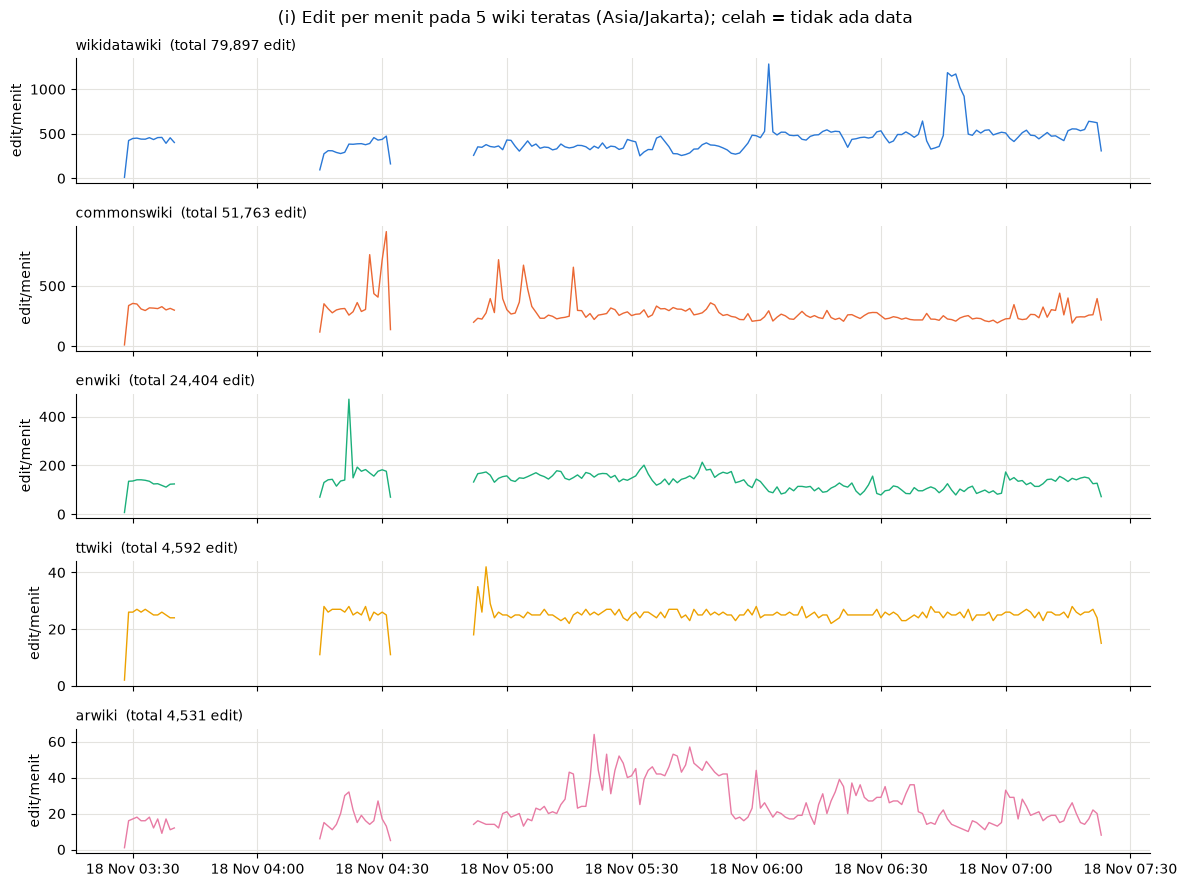

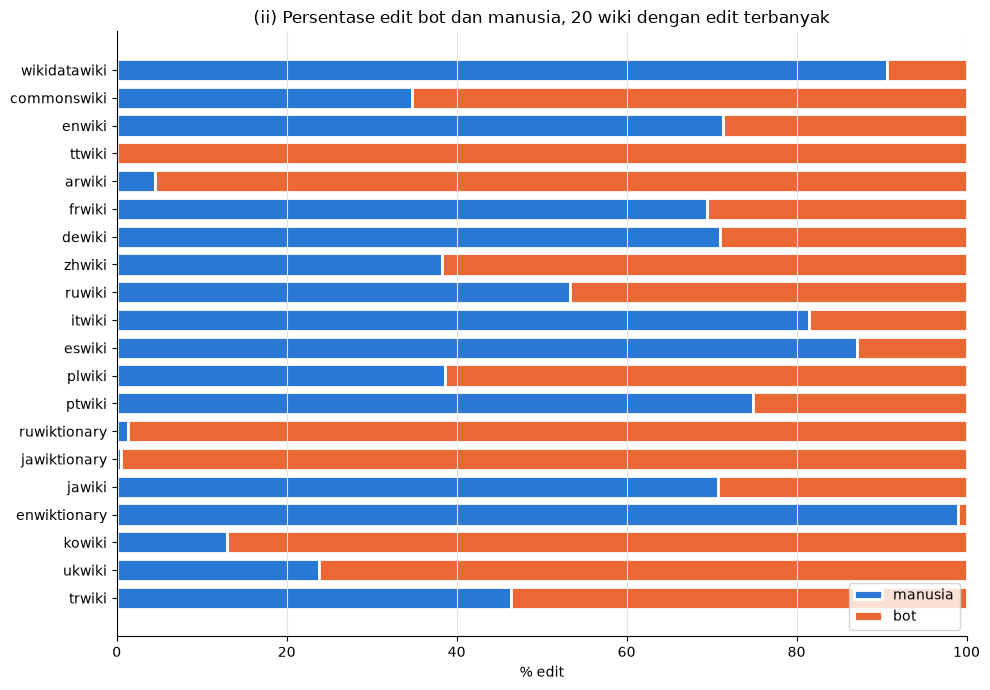

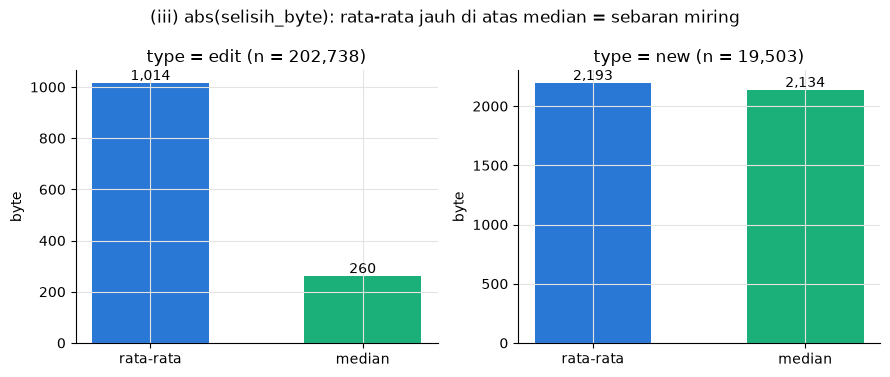

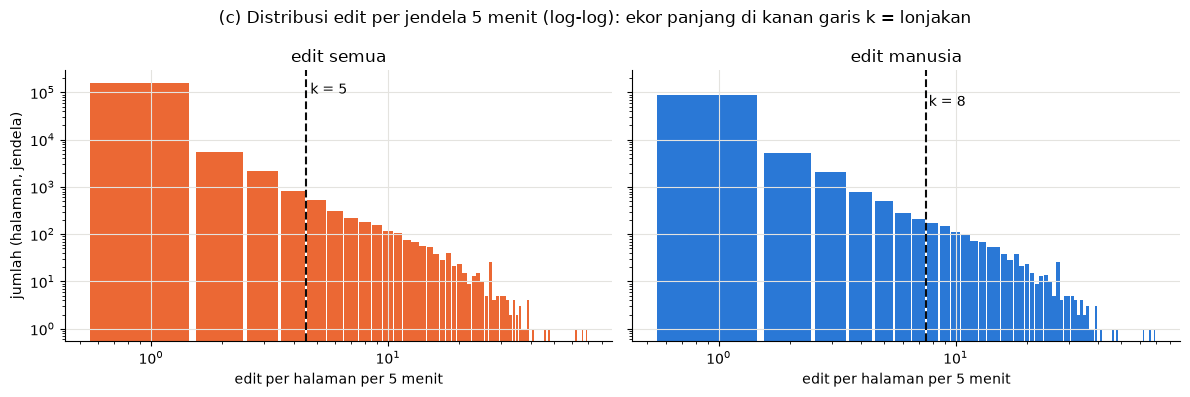

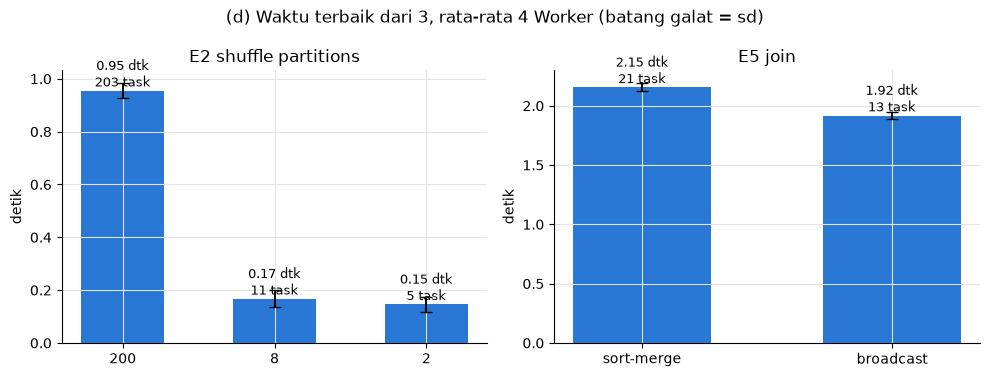

Gambar dan CSV tersimpan di C:\BigData\notebooks\laporan_soal3


In [12]:
# ===== SEL 12: Grafik =====
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e4e3df", "grid.linewidth": 0.8, "font.size": 10})
WARNA = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]     # urutan tetap, satu warna per wiki
BOT_C, MANUSIA_C = "#eb6834", "#2a78d6"

def simpan(fig, nama):
    fig.tight_layout(); fig.savefig(LAPORAN_DIR / f"{nama}.png", dpi=130); plt.show(); plt.close(fig)

# 1. (i) edit per menit 5 wiki teratas; menit tanpa data dibiarkan kosong (celah = producer mati)
d = H["i_deret"].copy(); d["menit"] = pd.to_datetime(d["menit"])
lengkap_menit = pd.date_range(d["menit"].min(), d["menit"].max(), freq="min")
fig, axs = plt.subplots(5, 1, figsize=(12, 9), sharex=True)
for ax, (w, c) in zip(axs, zip(H["i_top5"]["wiki"], WARNA)):
    s = d[d["wiki"] == w].set_index("menit")["n"].reindex(lengkap_menit)
    ax.plot(s.index, s.values, color=c, lw=1)
    ax.set_title(f"{w}  (total {int(s.sum()):,} edit)", loc="left", fontsize=10)
    ax.set_ylabel("edit/menit")
axs[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b %H:%M"))
fig.suptitle(f"(i) Edit per menit pada 5 wiki teratas ({ZONA}); celah = tidak ada data")
simpan(fig, "3b_i_per_menit")

# 2. (ii) persentase bot vs manusia, 20 wiki terbesar
ii = H["ii_bot_manusia"].head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(ii["wiki"], ii["persen_manusia"], color=MANUSIA_C, label="manusia", edgecolor="white", linewidth=2)
ax.barh(ii["wiki"], ii["persen_bot"], left=ii["persen_manusia"], color=BOT_C, label="bot", edgecolor="white", linewidth=2)
ax.set(xlim=(0, 100), xlabel="% edit", title="(ii) Persentase edit bot dan manusia, 20 wiki dengan edit terbanyak")
ax.legend(loc="lower right"); ax.grid(axis="y", visible=False)
simpan(fig, "3b_ii_bot_manusia")

# 3. (iii) rata-rata vs median abs(selisih_byte)
iii = H["iii_selisih"]
fig, axs = plt.subplots(1, len(iii), figsize=(4.5 * len(iii), 3.8), squeeze=False)
for ax, (_, r) in zip(axs[0], iii.iterrows()):
    ax.bar(["rata-rata", "median"], [r["rata_abs"], r["median_eksak"]], color=["#2a78d6", "#1baf7a"], width=0.55)
    for x, v in enumerate([r["rata_abs"], r["median_eksak"]]):
        ax.text(x, v, f"{v:,.0f}", ha="center", va="bottom")
    ax.set(title=f"type = {r['type']} (n = {int(r['n']):,})", ylabel="byte")
fig.suptitle("(iii) abs(selisih_byte): rata-rata jauh di atas median = sebaran miring")
simpan(fig, "3b_iii_selisih")

# 4. (c) histogram jumlah edit per (halaman, jendela 5 menit), sumbu log, dengan garis k
hist = spark.sql("SELECT kelompok, n, SUM(frekuensi) AS f FROM jendela_hist GROUP BY kelompok, n ORDER BY n").toPandas()
fig, axs = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, kel, c in zip(axs, ("semua", "manusia"), (BOT_C, MANUSIA_C)):
    h = hist[hist["kelompok"] == kel]
    ax.bar(h["n"], h["f"], color=c, width=0.9)
    ax.axvline(K[kel] - 0.5, color="#0b0b0b", lw=1.5, ls="--")
    ax.text(K[kel] - 0.3, h["f"].max(), f"k = {K[kel]}", va="top")
    ax.set(yscale="log", xscale="log", xlabel="edit per halaman per 5 menit", title=f"edit {kel}")
axs[0].set_ylabel("jumlah (halaman, jendela)")
fig.suptitle("(c) Distribusi edit per jendela 5 menit (log-log): ekor panjang di kanan garis k = lonjakan")
simpan(fig, "3c_distribusi_k")

# 5. (d) waktu percobaan optimasi, rata-rata ± sd antar-Worker
if ringkas_perf.empty:
    print("Grafik 3d dilewati: belum ada hasil performa.")
else:
    fig, axs = plt.subplots(1, 2, figsize=(10, 3.8))
    for ax, eks in zip(axs, ("E2 shuffle partitions", "E5 join")):
        s = ringkas_perf[ringkas_perf["eksperimen"] == eks]
        ax.bar(s["varian"].astype(str), s["rata_dtk"], yerr=s["sd_dtk"].fillna(0), capsize=4, color="#2a78d6", width=0.55)
        for x, (v, t) in enumerate(zip(s["rata_dtk"], s["n_task"])):
            ax.text(x, v, f"{v:.2f} dtk\n{t} task", ha="center", va="bottom", fontsize=9)
        ax.set(title=eks, ylabel="detik")
    fig.suptitle(f"(d) Waktu terbaik dari 3, rata-rata {waktu['worker'].nunique()} Worker (batang galat = sd)")
    simpan(fig, "3d_optimasi")
print("Gambar dan CSV tersimpan di", LAPORAN_DIR.resolve())

## Sel 13. Kirim ulang tugas yang belum lengkap / tutup

In [ ]:
# ===== SEL 13: Kirim ulang / tutup =====
belum = [t for t in range(JUMLAH_TUGAS) if t not in lengkap()]
print("Belum lengkap:", belum)
# kirim_tugas([t for t in SEMUA_TUGAS if t["tugas"] in belum])    # buka komentar untuk kirim ulang
# spark.stop()                                                      # tutup Spark setelah selesai